# CC1 — Réseaux de neurones : prédiction des prix de maisons
**Scikit-learn (`MLPRegressor`) vs TensorFlow/Keras**

## Introduction
On veut **prédire le prix d'une maison** à partir de ses caractéristiques (surface, nombre de chambres, etc.).
C'est un problème de **régression** (la cible est un nombre continu), donc :

> ❌ **On n'utilise pas l'accuracy**
> ✅ Métriques : **MAE, MSE, RMSE, R²**

⚠️ **Remarque sur le fichier utilisé** : le fichier fourni est `Housing.csv` (545 maisons, 12 variables) dont la **variable cible s'appelle `price`** (et non `SalePrice` comme dans `train.csv` de Kaggle *House Prices — Advanced Regression*). La démarche demandée est strictement la même ; seul le nom de la cible change. Le fichier est placé dans `Dataset/Housing.csv`.

## Dataset House Prices

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)

# Nom de la variable cible dans ce fichier
TARGET = 'price'

In [2]:
# Chargement du dataset
df = pd.read_csv('Dataset/Housing.csv')

print("Premières lignes :")
display(df.head())

print("Dimensions (lignes, colonnes) :", df.shape)

print("\nInformations sur les colonnes :")
df.info()

print("\nStatistiques descriptives (variables numériques) :")
display(df.describe())

Premières lignes :


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


Dimensions (lignes, colonnes) : (545, 13)

Informations sur les colonnes :
<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB

Statistiques descriptives (variables numériques) :


,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


Valeurs manquantes par colonne :
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Total de valeurs manquantes : 0


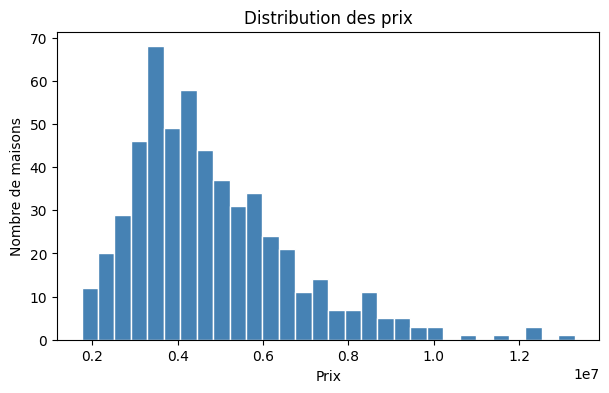

In [3]:
# Valeurs manquantes
missing = df.isnull().sum()
print("Valeurs manquantes par colonne :")
print(missing)
print("\nTotal de valeurs manquantes :", missing.sum())

# Distribution de la cible
plt.figure(figsize=(7, 4))
plt.hist(df[TARGET], bins=30, color='steelblue', edgecolor='white')
plt.title("Distribution des prix"); plt.xlabel("Prix"); plt.ylabel("Nombre de maisons")
plt.show()

## Préparation des données
1. **Séparer** `X` (variables explicatives) et `y` (le prix).
2. **Variables numériques** : on garde les colonnes numériques. Dans ce fichier, 5 colonnes sont déjà numériques (`area`, `bedrooms`, `bathrooms`, `stories`, `parking`) et 6 colonnes sont de simples **oui/non** (`mainroad`, `guestroom`, ...). On convertit ces dernières en **0/1** (opération triviale) afin de ne pas perdre d'information importante. La colonne `furnishingstatus` (3 catégories) est transformée par *one-hot encoding*.
3. **Valeurs manquantes** : remplacées par la **médiane** de chaque colonne (ici il n'y en a aucune, mais le code est prêt pour un autre fichier).

In [4]:
# 1) Séparation X / y
y = df[TARGET]
X = df.drop(columns=[TARGET])

# 2) Encodage simple des variables catégorielles
binary_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for col in binary_cols:
    X[col] = X[col].map({'yes': 1, 'no': 0})
X = pd.get_dummies(X, columns=['furnishingstatus'], drop_first=True, dtype=int)

# On ne garde que les colonnes numériques
X = X.select_dtypes(include='number')

# 3) Remplacement des valeurs manquantes par la médiane
X = X.fillna(X.median())

print("Variables utilisées :", list(X.columns))
print("Forme de X :", X.shape)

Variables utilisées : ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']
Forme de X : (545, 13)


## Division train/test et standardisation
On standardise `X`. Ici, **on standardise aussi la cible `y`** : les prix valent plusieurs millions, alors que les variables standardisées sont autour de 0. Sans cela, les réseaux apprennent très lentement. 
Pour évaluer le modèle, on **reconvertit les prédictions en prix réels** (`inverse_transform`), donc **toutes les métriques sont exprimées dans l'unité d'origine du prix**.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("Train :", X_train.shape, " Test :", X_test.shape)

# Standardisation de X (fit sur le train uniquement)
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# Standardisation de y
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).ravel()

# Fonction qui calcule les 4 métriques de régression (en unité réelle)
def regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return mae, mse, rmse, r2

Train : (436, 13)  Test : (109, 13)


---
# Partie 1 : MLPRegressor — Scikit-learn

## Entraînement
Architecture : `variables → 64 neurones → 32 neurones → 1 sortie (prix)`.
- `early_stopping=True` : l'entraînement s'arrête quand le score de validation (10 % du train) ne s'améliore plus → évite le sur-apprentissage.

In [6]:
mlp_reg = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000,
                       early_stopping=True, n_iter_no_change=20, random_state=SEED)

start = time.time()
mlp_reg.fit(X_train_scaled, y_train_scaled)
time_sk_house = time.time() - start
print(f"Entraînement terminé en {time_sk_house:.3f} s ({mlp_reg.n_iter_} itérations)")

Entraînement terminé en 0.430 s (82 itérations)


## Prédiction et métriques (MAE, MSE, RMSE, R²)

In [7]:
# Prédiction (en échelle standardisée) puis retour à l'échelle réelle des prix
y_pred_sk_scaled = mlp_reg.predict(X_test_scaled)
y_pred_sk = scaler_y.inverse_transform(y_pred_sk_scaled.reshape(-1, 1)).ravel()

mae_sk, mse_sk, rmse_sk, r2_sk = regression_metrics(y_test, y_pred_sk)

print(f"MAE  : {mae_sk:,.0f}")
print(f"MSE  : {mse_sk:,.0f}")
print(f"RMSE : {rmse_sk:,.0f}")
print(f"R²   : {r2_sk:.4f}")

MAE  : 1,041,123
MSE  : 1,889,066,528,417
RMSE : 1,374,433
R²   : 0.6263


- **MAE** : erreur absolue moyenne (en unités de prix) ;
- **MSE** : moyenne des erreurs au carré (pénalise fortement les grosses erreurs) ;
- **RMSE** : racine du MSE, dans la même unité que le prix ;
- **R²** : part de la variance du prix expliquée par le modèle (1 = parfait, 0 = pas mieux que prédire la moyenne).

## Courbe de loss et prix réels vs prédits

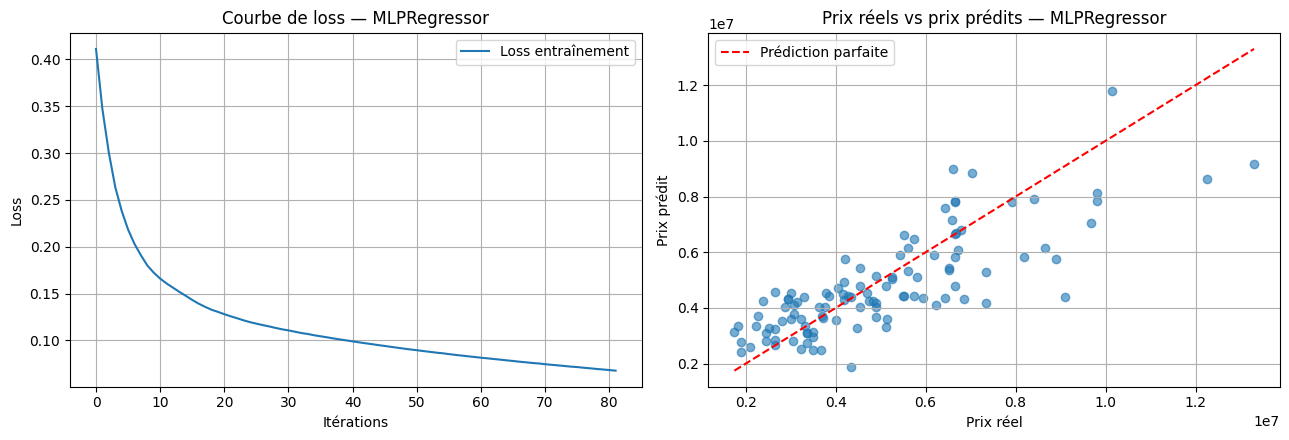

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Courbe de loss (échelle standardisée)
axes[0].plot(mlp_reg.loss_curve_, label='Loss entraînement')
axes[0].set_title("Courbe de loss — MLPRegressor")
axes[0].set_xlabel("Itérations"); axes[0].set_ylabel("Loss"); axes[0].legend(); axes[0].grid(True)

# Réel vs prédit
axes[1].scatter(y_test, y_pred_sk, alpha=0.6)
lims = [min(y_test.min(), y_pred_sk.min()), max(y_test.max(), y_pred_sk.max())]
axes[1].plot(lims, lims, 'r--', label='Prédiction parfaite')
axes[1].set_title("Prix réels vs prix prédits — MLPRegressor")
axes[1].set_xlabel("Prix réel"); axes[1].set_ylabel("Prix prédit"); axes[1].legend(); axes[1].grid(True)

plt.tight_layout(); plt.show()

## Interprétation — Scikit-learn

*(Valeurs observées lors de l'exécution ; elles peuvent varier légèrement selon la machine et les versions.)*

- **R² ≈ 0,63** : le modèle explique environ 63 % de la variance des prix. C'est un résultat correct mais loin d'être parfait.
- **MAE ≈ 1,04 million** et **RMSE ≈ 1,37 million**, à comparer avec un prix moyen d'environ 4,77 millions : l'erreur typique représente donc **environ 20 %** du prix moyen.
- Le RMSE est supérieur au MAE : quelques maisons (surtout les plus chères) sont prédites avec de **grosses erreurs**.
- Sur le graphique réel/prédit, les points suivent globalement la diagonale mais **s'en écartent pour les prix élevés** : le modèle a tendance à sous-estimer les maisons les plus chères.
- L'entraînement s'est arrêté tôt grâce à l'*early stopping* (le dataset ne compte que 436 exemples d'entraînement).

---
# Partie 2 : TensorFlow/Keras — Régression House Prices

## Préparation
On réutilise **les mêmes variables, le même découpage train/test et la même standardisation** que dans la Partie 1.

In [9]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(SEED)
print("Version de TensorFlow :", tf.__version__)
print("Nombre de variables d'entrée :", X_train_scaled.shape[1])

Version de TensorFlow : 2.21.0
Nombre de variables d'entrée : 13


## Construction du réseau
`Input → Dense(64, ReLU) → Dense(32, ReLU) → Dense(16, ReLU) → Dense(1)`
- La **sortie n'a pas d'activation** (linéaire) : on veut un nombre réel quelconque ;
- **Loss = MSE** (adaptée à la régression), métriques **MAE** et **MSE**.

In [10]:
n_features = X_train_scaled.shape[1]

model_house = Sequential([
    Input(shape=(n_features,)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1)                      # sortie : le prix (standardisé)
])

model_house.compile(optimizer='adam', loss='mse', metrics=['mae', 'mse'])
model_house.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,521 (13.75 KB)

 Trainable params: 3,521 (13.75 KB)

 Non-trainable params: 0 (0.00 B)

## Entraînement
`EarlyStopping` arrête l'entraînement quand la loss de validation ne s'améliore plus pendant 20 epochs et restaure les meilleurs poids.

In [11]:
early_stop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

start = time.time()
history_house = model_house.fit(
    X_train_scaled, y_train_scaled,
    epochs=300, batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=0
)
time_keras_house = time.time() - start
print(f"Entraînement terminé en {time_keras_house:.2f} s ({len(history_house.history['loss'])} epochs)")

Entraînement terminé en 18.53 s (44 epochs)


## Courbes d'apprentissage

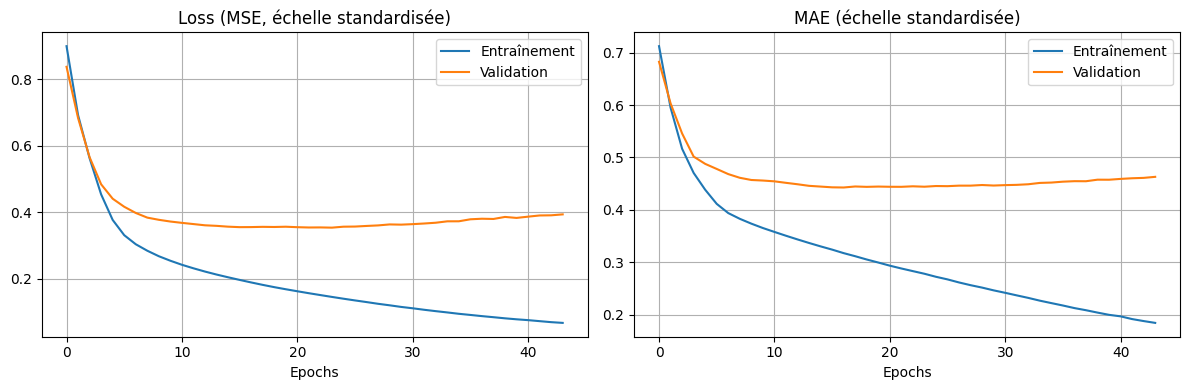

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_house.history['loss'], label='Entraînement')
axes[0].plot(history_house.history['val_loss'], label='Validation')
axes[0].set_title("Loss (MSE, échelle standardisée)"); axes[0].set_xlabel("Epochs"); axes[0].legend(); axes[0].grid(True)

axes[1].plot(history_house.history['mae'], label='Entraînement')
axes[1].plot(history_house.history['val_mae'], label='Validation')
axes[1].set_title("MAE (échelle standardisée)"); axes[1].set_xlabel("Epochs"); axes[1].legend(); axes[1].grid(True)

plt.tight_layout(); plt.show()

## Prédiction et métriques (MAE, MSE, RMSE, R²)

In [13]:
y_pred_keras_scaled = model_house.predict(X_test_scaled, verbose=0).ravel()
y_pred_keras = scaler_y.inverse_transform(y_pred_keras_scaled.reshape(-1, 1)).ravel()

mae_keras, mse_keras, rmse_keras, r2_keras = regression_metrics(y_test, y_pred_keras)

print(f"MAE  : {mae_keras:,.0f}")
print(f"MSE  : {mse_keras:,.0f}")
print(f"RMSE : {rmse_keras:,.0f}")
print(f"R²   : {r2_keras:.4f}")

MAE  : 1,003,892
MSE  : 1,833,071,280,128
RMSE : 1,353,910
R²   : 0.6373


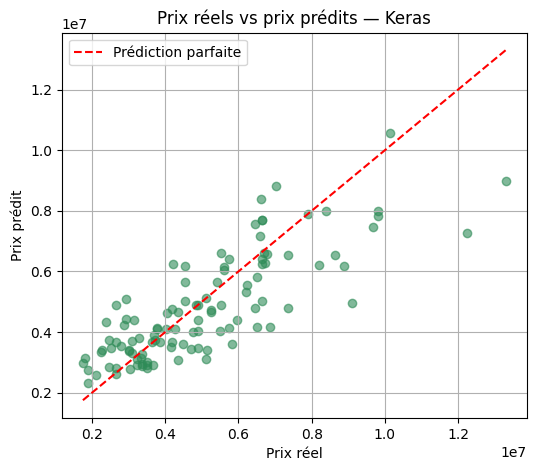

In [14]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred_keras, alpha=0.6, color='seagreen')
lims = [min(y_test.min(), y_pred_keras.min()), max(y_test.max(), y_pred_keras.max())]
plt.plot(lims, lims, 'r--', label='Prédiction parfaite')
plt.title("Prix réels vs prix prédits — Keras")
plt.xlabel("Prix réel"); plt.ylabel("Prix prédit"); plt.legend(); plt.grid(True)
plt.show()

## Interprétation — Keras

- **R² ≈ 0,64**, **MAE ≈ 1,00 million**, **RMSE ≈ 1,35 million** : des résultats du même ordre que ceux de `MLPRegressor`.
- Les **courbes d'apprentissage** montrent la loss de validation qui cesse de diminuer assez tôt alors que celle d'entraînement continue de baisser : c'est le début du **sur-apprentissage**, ce qui est normal avec peu de données. `EarlyStopping` arrête l'entraînement au bon moment.
- Le graphique réel/prédit présente la même tendance que pour Scikit-learn : une bonne corrélation, mais des écarts importants pour les prix élevés.

---
# Comparaison Sklearn vs Keras

,Modèle,Framework,MAE,RMSE,R²,Temps entraînement (s)
0,MLPRegressor,Scikit-learn,1.041123e+06,1.374433e+06,0.6263,0.4296
1,Neural Network,TensorFlow/Keras,1.003892e+06,1.353910e+06,0.6373,18.5270


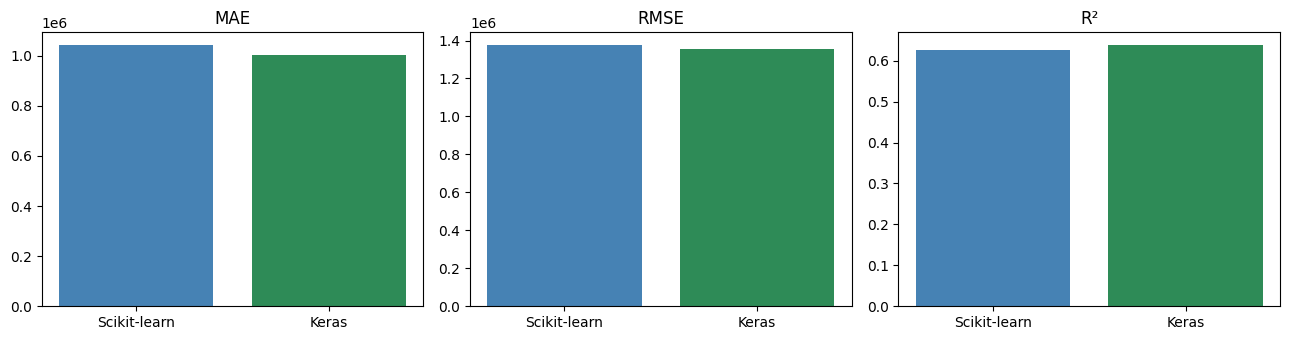

Métriques gagnées -> Scikit-learn : 0/3 | Keras : 3/3
➜ Meilleur modèle : Neural Network (Keras)


In [15]:
comparison_house = pd.DataFrame({
    'Modèle': ['MLPRegressor', 'Neural Network'],
    'Framework': ['Scikit-learn', 'TensorFlow/Keras'],
    'MAE': [mae_sk, mae_keras],
    'RMSE': [rmse_sk, rmse_keras],
    'R²': [r2_sk, r2_keras],
    'Temps entraînement (s)': [time_sk_house, time_keras_house],
})
display(comparison_house.round(4))

# Graphique comparatif
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ['MAE', 'RMSE', 'R²']):
    ax.bar(['Scikit-learn', 'Keras'], comparison_house[col], color=['steelblue', 'seagreen'])
    ax.set_title(col)
plt.tight_layout(); plt.show()

# Verdict automatique : un point par métrique gagnée
points_sk = int(mae_sk < mae_keras) + int(rmse_sk < rmse_keras) + int(r2_sk > r2_keras)
points_keras = 3 - points_sk
print(f"Métriques gagnées -> Scikit-learn : {points_sk}/3 | Keras : {points_keras}/3")
print("➜ Meilleur modèle :", "MLPRegressor (Scikit-learn)" if points_sk > points_keras else "Neural Network (Keras)")

Rappel : **MAE plus faible → meilleur**, **RMSE plus faible → meilleur**, **R² plus élevé → meilleur**.


### Interprétation
Dans notre exécution, le réseau **Keras est meilleur sur les trois métriques** (MAE, RMSE plus faibles et R² plus élevé), mais **l'avantage est très faible** : environ 37 000 de MAE (≈ 4 %) et 0,011 de R². Cet écart est du même ordre que la variabilité due à l'initialisation aléatoire et au découpage des données ; on ne peut donc pas conclure qu'un framework est réellement meilleur. **Les deux modèles ont pratiquement la même performance.**

Côté temps, Scikit-learn est beaucoup plus rapide sur ce petit dataset.

---
# Conclusion

**1. Quel modèle est le meilleur ?**
Dans notre exécution, le **réseau Keras** est légèrement meilleur (MAE ≈ 1,00 M, RMSE ≈ 1,35 M, R² ≈ 0,64 contre 1,04 M, 1,37 M et 0,63 pour `MLPRegressor`). La différence est cependant **minime**.

**2. Pourquoi ?**
Les deux modèles apprennent la même relation avec les mêmes données : la performance est limitée par la **qualité et la quantité des données** (545 maisons seulement, 13 variables) plus que par le framework. Le petit avantage de Keras peut venir de sa couche supplémentaire (64-32-16 vs 64-32) et de son entraînement avec validation et `EarlyStopping`, mais aussi du simple hasard de l'initialisation.

**3. Différence entre Scikit-learn et TensorFlow/Keras**
`MLPRegressor` est simple d'emploi (quelques lignes, `fit`/`predict`) mais peu configurable. Keras demande plus de code mais donne le contrôle de chaque couche, de la loss, des métriques suivies et des callbacks, et fournit l'historique d'entraînement train/validation.

**4. Avantages et inconvénients**

| | Avantages | Inconvénients |
|---|---|---|
| **Scikit-learn (MLPRegressor)** | Simple, rapide, intégré aux pipelines et à la validation croisée | Peu de contrôle, pas de GPU, pas de callbacks avancés |
| **TensorFlow/Keras** | Flexible, suivi complet de l'apprentissage, adapté aux gros modèles et aux gros volumes | Plus verbeux, plus lent sur petit dataset, davantage d'hyperparamètres à régler |

**5. Que peut-on améliorer ?**
- **Transformer la cible** (par exemple `log(price)`) pour réduire l'effet des prix très élevés ;
- **Ajouter des variables / du feature engineering** et tester d'autres encodages des variables catégorielles ;
- Utiliser la **validation croisée** et plusieurs graines aléatoires pour des comparaisons plus fiables ;
- **Régulariser** le réseau (`alpha` en sklearn, `Dropout` / `L2` en Keras) et ajuster les hyperparamètres (taille des couches, learning rate) ;
- Comparer avec des modèles d'arbres (Random Forest, Gradient Boosting), souvent plus performants sur ce type de données tabulaires.